# Implementación de modelo predictivo de extinción de flama con modelo de supervivencia de Cox

In [48]:
import importlib.util
import duckdb
from flamesafe import config
from pathlib import Path

# Find the helper file in the current project tree
module_path = next(Path.cwd().glob("**/03_m2_flame_survival_cox*.py"), None)

if module_path is None:
    raise FileNotFoundError(
        "Could not find the Cox survival helper file (expected: 03_m2_flame_survival_cox*.py)"
    )

spec = importlib.util.spec_from_file_location("m2_flame_survival_cox", module_path)
module = importlib.util.module_from_spec(spec)
assert spec is not None and spec.loader is not None
spec.loader.exec_module(module)

# Match the symbol name expected elsewhere in the notebook
m2_flame_survival_cox = getattr(module, "m2_flame_survival_cox", module)
cs = m2_flame_survival_cox

Importación de datos

In [49]:
con = duckdb.connect(str(config.data_dir() / "gold" / "flamesafe.duckdb"), read_only=True)
gas = con.sql("SELECT * FROM gas_flame_tests").df()
con.close()

Preparación de datos y construcción de modelos

In [85]:
df, flujo = cs.preparar_datos(gas)

modelos = cs.construir_modelos(df)
modelos

{'M1_diseno': ['fuel_ethane', 'fuel_propane', 'normal'],
 'M2_atmosfera': ['fuel_ethane',
  'fuel_propane',
  'normal',
  'xo2_5pp',
  'p_10kpa'],
 'M3_interaccion': ['fuel_ethane',
  'fuel_propane',
  'normal',
  'xo2_5pp',
  'p_10kpa',
  'xo2_x_normal']}

In [51]:
# Diagnóstico previo
diag = {}
vif = {}
cobertura = {}
for i in range(len(modelos)):
    cov = list(modelos.values())[i]
    print(f"Modelo {list(modelos.keys())[i]}:")
    diag[i], vif[i], cobertura[i] = cs.diagnostico_previo(df, covs=cov)
    print(diag[i].to_string())
    print(vif[i].to_string())
    print(cobertura[i].to_string())

Modelo M1_diseno:
n                        272.0
eventos                  183.0
censuras                  89.0
pct_censura               32.7
parametros                 3.0
eventos_por_parametro     61.0
pct_tiempos_empatados     63.6
censura_moda_s            66.0
pct_censura_en_moda       29.2
fuel_ethane     1.24
fuel_propane    1.24
normal          1.00
flame_type inverse     normal    
evento           0   1      0   1
fuel                             
butane          23  30     15  38
ethane          22  27     10  30
propane         13  24      6  34
Modelo M2_atmosfera:
n                        272.0
eventos                  183.0
censuras                  89.0
pct_censura               32.7
parametros                 5.0
eventos_por_parametro     36.6
pct_tiempos_empatados     63.6
censura_moda_s            66.0
pct_censura_en_moda       29.2
fuel_ethane     1.30
fuel_propane    1.27
normal          1.58
xo2_5pp         1.58
p_10kpa         1.14
flame_type inverse     normal  

In [52]:

cph = {}

for i in range(len(modelos)):
    cov = list(modelos.values())[i]
    print(f"Modelo {list(modelos.keys())[i]}:")
    cph[i] = cs.ajustar_cox(df, covs=cov)
    print(cph[i].summary.to_string())

Modelo M1_diseno:
                  coef  exp(coef)  se(coef)  coef lower 95%  coef upper 95%  exp(coef) lower 95%  exp(coef) upper 95%  cmp to         z         p  -log2(p)
covariate                                                                                                                                                  
fuel_ethane  -0.173742   0.840514  0.182249       -0.530944        0.183460             0.588050             1.201367     0.0 -0.953320  0.340428  1.554579
fuel_propane  0.405592   1.500191  0.180485        0.051849        0.759336             1.053217             2.136857     0.0  2.247241  0.024625  5.343755
normal       -0.041836   0.959027  0.154540       -0.344728        0.261056             0.708413             1.298300     0.0 -0.270715  0.786610  0.346280
Modelo M2_atmosfera:
                  coef  exp(coef)  se(coef)  coef lower 95%  coef upper 95%  exp(coef) lower 95%  exp(coef) upper 95%  cmp to         z             p   -log2(p)
covariate           

In [53]:
t = {}
for i in range(len(cph)):
    t[i] = cs.tabla_estimadores(cph[i])
    print(t[i])

                  coef  coef_IC_inf  ...         p    p_holm
covariate                            ...                    
fuel_ethane  -0.173742    -0.530944  ...  0.340428  0.680856
fuel_propane  0.405592     0.051849  ...  0.024625  0.073874
normal       -0.041836    -0.344728  ...  0.786610  0.786610

[3 rows x 9 columns]
                  coef  coef_IC_inf  ...             p        p_holm
covariate                            ...                            
fuel_ethane  -0.099153    -0.457004  ...  5.870841e-01  9.500920e-01
fuel_propane  0.493749     0.135515  ...  6.905023e-03  2.762009e-02
normal        0.226466    -0.158904  ...  2.494073e-01  7.482218e-01
xo2_5pp      -0.014349    -0.053723  ...  4.750460e-01  9.500920e-01
p_10kpa       0.064514     0.047214  ...  2.687758e-13  1.343879e-12

[5 rows x 9 columns]
                  coef  coef_IC_inf  ...             p        p_holm
covariate                            ...                            
fuel_ethane  -0.351719    -0.7

In [54]:
s = {}
for i in range(len(cph)):
    s[i] = cs.resumen_global(cph[i])
    print(s[i])

LR_chi2              9.727526
gl                   3.000000
p_LR                 0.021030
logLik_parcial    -890.534264
AIC_parcial       1787.068528
C_aparente           0.588716
dtype: float64
LR_chi2           6.197153e+01
gl                5.000000e+00
p_LR              4.753456e-12
logLik_parcial   -8.644123e+02
AIC_parcial       1.738825e+03
C_aparente        6.874221e-01
dtype: float64
LR_chi2           1.405362e+02
gl                6.000000e+00
p_LR              7.723218e-28
logLik_parcial   -8.251299e+02
AIC_parcial       1.662260e+03
C_aparente        7.453081e-01
dtype: float64


In [60]:
e = {}
for i,j in zip(list(modelos.values()), range(len(modelos))):
    e[j] = cs.comparar_errores_estandar(df, i)
    print(e[j])

              ee_modelo  ee_robusto  HR_IC_inf_rob  HR_IC_sup_rob  cociente
covariate                                                                  
fuel_ethane    0.182249    0.337454       0.433814       1.628494  1.851607
fuel_propane   0.180485    0.502869       0.559892       4.019659  2.786214
normal         0.154540    0.330127       0.502142       1.831619  2.136194
              ee_modelo  ee_robusto  HR_IC_inf_rob  HR_IC_sup_rob  cociente
covariate                                                                  
fuel_ethane    0.182580    0.303974       0.499108       1.643166  1.664878
fuel_propane   0.182776    0.380809       0.776761       3.456034  2.083475
normal         0.196621    0.279430       0.725273       2.168724  1.421165
xo2_5pp        0.020089    0.029710       0.929992       1.044857  1.478914
p_10kpa        0.008826    0.013654       1.038474       1.095570  1.546935
              ee_modelo  ee_robusto  HR_IC_inf_rob  HR_IC_sup_rob  cociente
covariate   

In [62]:
ics = {}
for i,j in zip(list(modelos.values()), range(len(modelos))):
    ics[j] = cs.bootstrap_parametros(df, i)
    print(ics[j])

              HR_boot_inf  HR_boot_sup
covariate                             
fuel_ethane      0.600901     1.176116
fuel_propane     1.083688     2.241025
normal           0.686445     1.312856
              HR_boot_inf  HR_boot_sup
covariate                             
fuel_ethane      0.604264     1.334770
fuel_propane     1.160903     2.463052
normal           0.762742     2.022188
xo2_5pp          0.932745     1.033924
p_10kpa          1.048480     1.091437
              HR_boot_inf  HR_boot_sup
covariate                             
fuel_ethane      0.463896     1.077095
fuel_propane     0.739728     1.597969
normal          74.660499  1089.129425
xo2_5pp          0.976198     1.122097
p_10kpa          1.053309     1.098837
xo2_x_normal     0.411486     0.552029


Chequeo de supuestos para el modelo ['fuel_ethane', 'fuel_propane', 'normal']:
{'prueba_PH':               test_statistic         p  -log2(p)    p_holm
fuel_ethane         0.023099  0.879201  0.185735  0.879201
fuel_propane        2.646665  0.103767  3.268575  0.207535
normal             10.530381  0.001174  9.734008  0.003523, 'n_influyentes_por_coef': covariate
fuel_ethane     0
fuel_propane    0
normal          0
dtype: int64, 'umbral_dfbetas': np.float64(0.12126781251816648), 'top_influyentes': 40     0.101272
36     0.091921
97     0.085134
89     0.085134
84     0.085134
71     0.082305
70     0.079350
214    0.076593
122    0.072368
216    0.072207
dtype: float64, 'figuras': {'schoenfeld': <Figure size 960x320 with 3 Axes>}}
Chequeo de censura para el modelo ['fuel_ethane', 'fuel_propane', 'normal']:
(                  coef  coef_IC_inf  ...             p        p_holm
covariate                            ...                            
fuel_ethane  -0.302299    -0.784950  ...  

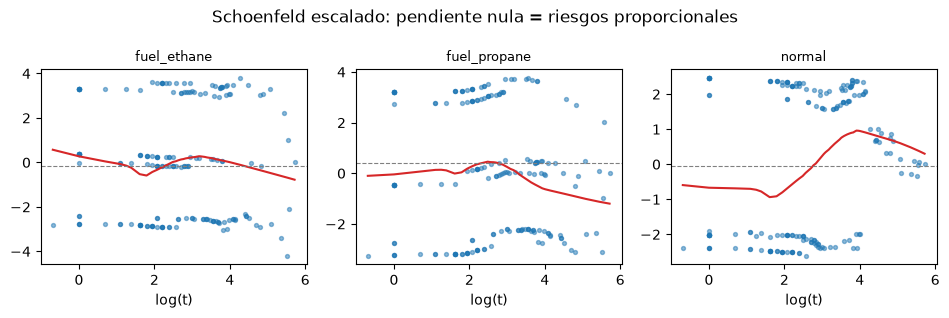

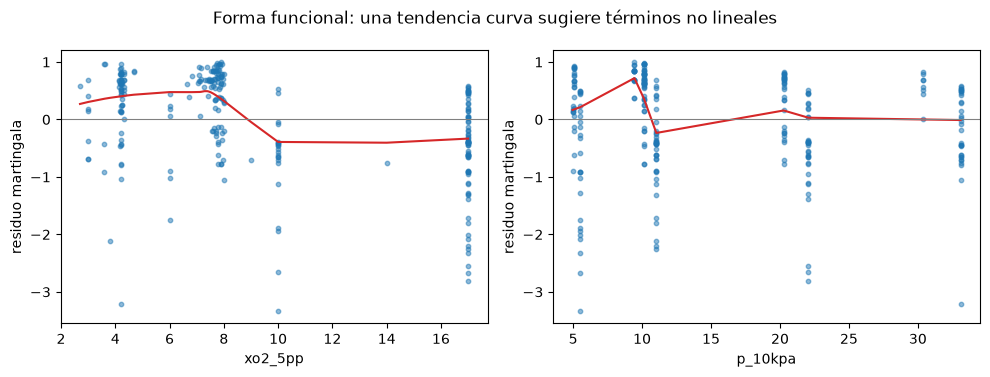

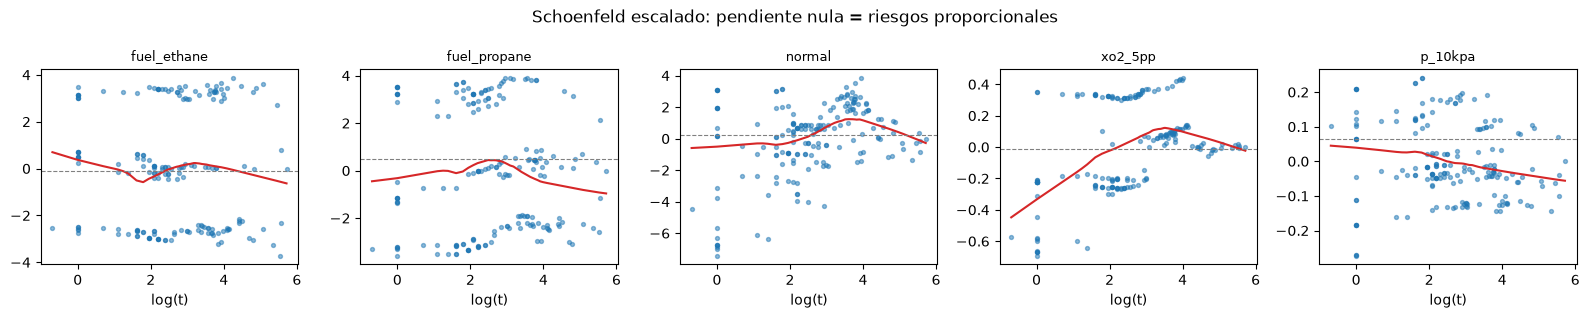

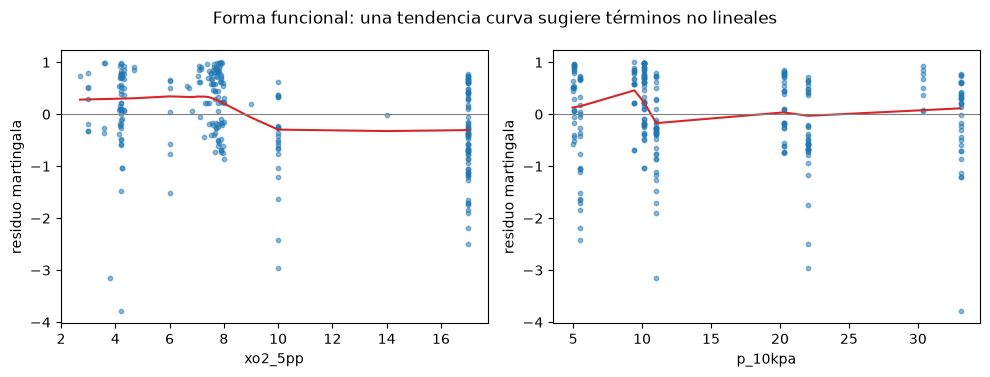

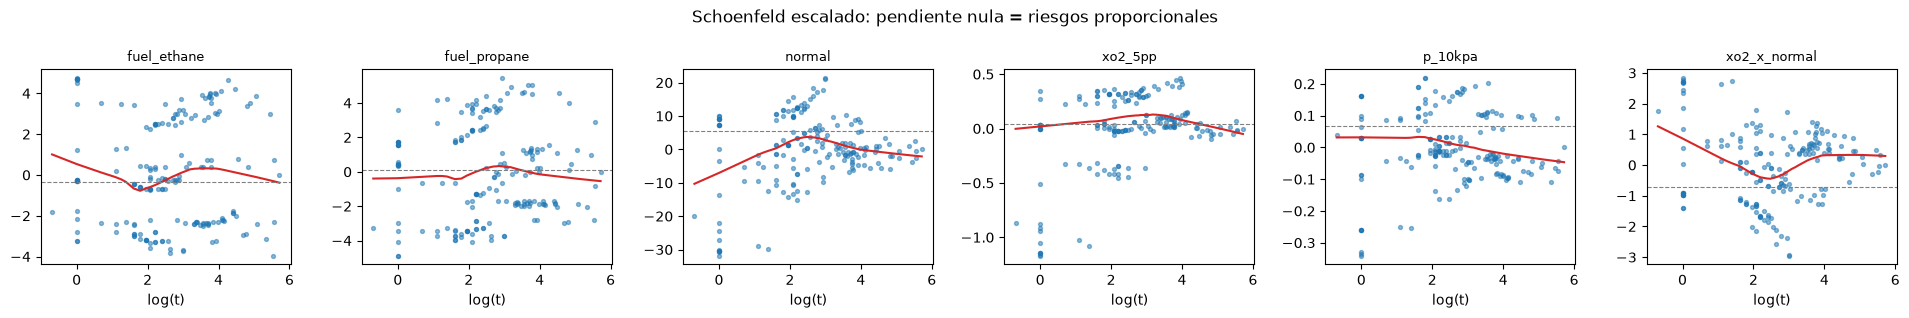

In [67]:
for i, _, k in zip(cph.values(), df, list(modelos.values())):
    check = cs.chequeo_supuestos(i, df, k)
    print(f"Chequeo de supuestos para el modelo {k}:")
    print(check)
    check2 = cs.chequeo_censura(df, k)
    print(f"Chequeo de censura para el modelo {k}:")
    print(check2)

In [68]:
for i in  list(modelos.values()):
    check2 = cs.chequeo_censura(df, i)
    print(f"Chequeo de censura para el modelo {i}:")
    print(check2)
    sensibilidad = cs.sensibilidad_censura(df, i)
    print(f"Sensibilidad a la censura para el modelo {i}:")
    print(sensibilidad)

Chequeo de censura para el modelo ['fuel_ethane', 'fuel_propane', 'normal']:
(                  coef  coef_IC_inf  ...             p        p_holm
covariate                            ...                            
fuel_ethane  -0.302299    -0.784950  ...  2.196020e-01  4.392040e-01
fuel_propane -0.191455    -0.751602  ...  5.029181e-01  5.029181e-01
normal       -1.487098    -1.986210  ...  5.229662e-09  1.568898e-08

[3 rows x 9 columns], LR_chi2    3.934646e+01
gl         3.000000e+00
p          1.465758e-08
dtype: float64)
Sensibilidad a la censura para el modelo ['fuel_ethane', 'fuel_propane', 'normal']:
     covariable                     escenario  ...  HR_IC_inf  HR_IC_sup
0   fuel_ethane          principal: censurado  ...   0.588050   1.201367
1  fuel_propane          principal: censurado  ...   1.053217   2.136857
2        normal          principal: censurado  ...   0.708413   1.298300
3   fuel_ethane  extremo: tratado como evento  ...   0.599464   1.064152
4  fuel_propane  

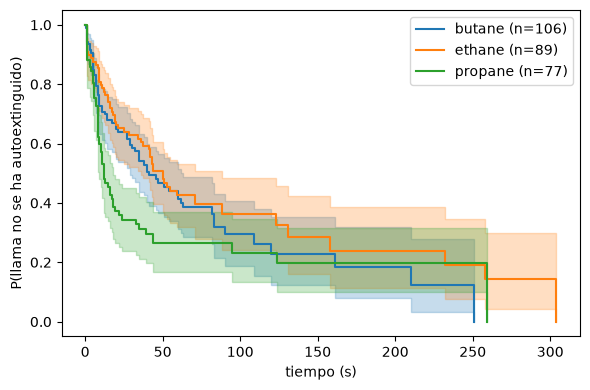

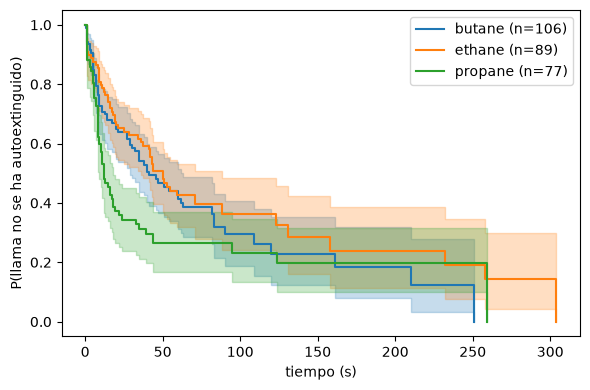

In [69]:
cs.grafico_km(df)

        T  E  cluster        lp  ...      S_55     S0_55      S_60     S0_60
0    50.0  1        1 -0.448506  ...  0.534693  0.376101  0.516704  0.357903
1    43.0  1        1 -0.448506  ...  0.534693  0.376101  0.516704  0.357903
2    42.0  1        1 -0.448506  ...  0.534693  0.376101  0.516704  0.357903
3    61.0  0        1 -0.448506  ...  0.534693  0.376101  0.516704  0.357903
4    28.0  0        1 -0.448506  ...  0.534693  0.376101  0.516704  0.357903
..    ... ..      ...       ...  ...       ...       ...       ...       ...
267  66.0  0       12  0.000000  ...  0.227621  0.347146  0.216843  0.335575
268  66.0  0       12  0.000000  ...  0.227621  0.347146  0.216843  0.335575
269  66.0  0       12  0.000000  ...  0.227621  0.347146  0.216843  0.335575
270  55.0  0       12  0.000000  ...  0.227621  0.347146  0.216843  0.335575
271  40.0  0       12  0.000000  ...  0.227621  0.347146  0.216843  0.335575

[272 rows x 28 columns]
[( True,  50. ) ( True,  43. ) ( True,  42. ) (Fals

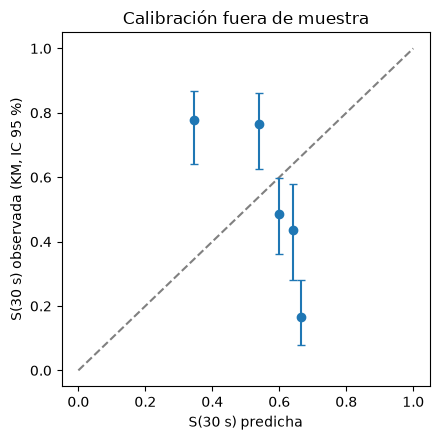

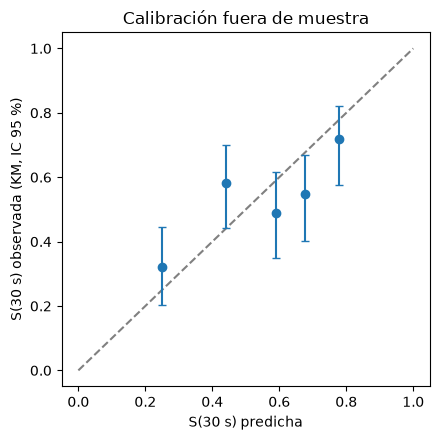

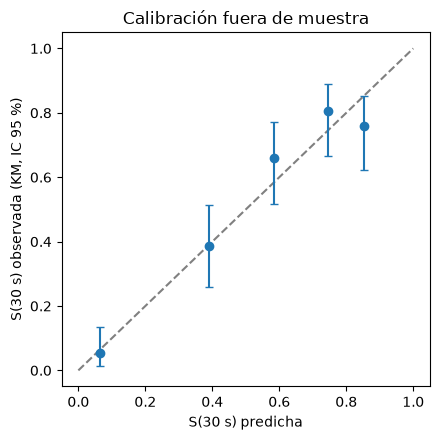

In [ ]:

for i in range(len(modelos)):
    cov = list(modelos.values())[i]
    o = cs.validacion_cruzada(df, covs=cov)
    y = cs._y(o)
    print(o)
    print(y)
    m = cs.metricas_oof(o)
    print(m)
    icm = cs.ic_metricas(o)
    print(icm)
    cal = cs.calibracion(o, 30)
    print(cal)
    graf = cs.grafico_calibracion(cal, 30)



In [89]:
for i in range(1, len(modelos)):
   o = cs.validacion_cruzada(df, covs=cov)
   clasif = cs.clasificacion_ipcw(o, 30)
   print(clasif)
   icc = cs.ic_clasificacion(o, 30, umbrales=(0.05,0.01))
   print(icc)


sensibilidad            0.860465
especificidad           0.670098
VPP                     0.747030
VPN                     0.809221
exactitud_balanceada    0.765281
prevalencia_persiste    0.530999
umbral                  0.500000
dtype: float64
        estimador            ...                                  
metrica       VPN       VPP  ... exactitud_balanceada sensibilidad
umbral                       ...                                  
0.01          1.0  0.547105  ...             0.553656          1.0
0.05          1.0  0.568665  ...             0.600168          1.0

[2 rows x 15 columns]
sensibilidad            0.860465
especificidad           0.670098
VPP                     0.747030
VPN                     0.809221
exactitud_balanceada    0.765281
prevalencia_persiste    0.530999
umbral                  0.500000
dtype: float64
        estimador            ...                                  
metrica       VPN       VPP  ... exactitud_balanceada sensibilidad
umbral          

In [90]:
cs.comparar_modelos(df, modelos)

,n_param,AIC_parcial,C_Harrell,C_Uno,AUC_60,IBS,IPA_IBS
modelo,,,,,,,
M1_diseno,3,1787.068528,"0.396 [0.365, 0.438]","0.399 [0.368, 0.442]","0.354 [0.285, 0.426]","0.288 [0.272, 0.301]","-0.165 [-0.209, -0.117]"
M2_atmosfera,5,1738.824523,"0.636 [0.583, 0.682]","0.636 [0.584, 0.682]","0.608 [0.523, 0.674]","0.232 [0.214, 0.251]","0.062 [-0.016, 0.131]"
M3_interaccion,6,1662.259857,"0.707 [0.665, 0.747]","0.706 [0.662, 0.746]","0.714 [0.655, 0.775]","0.177 [0.157, 0.200]","0.283 [0.191, 0.362]"
